In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

In [2]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "flower_photos", validation_split=0.2, subset="training",
    seed=42, image_size=(150, 150), batch_size=32)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "flower_photos", validation_split=0.2, subset="validation",
    seed=42, image_size=(150, 150), batch_size=32)

class_names = train_ds.class_names
num_classes = len(class_names)
print(class_names)

train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
test_ds = test_ds.map(lambda x, y: (preprocess_input(x), y))

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [3]:
# a. Load pre-trained CNN
base_model = VGG16(weights="vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5",
                   include_top=False, input_shape=(150, 150, 3))

# b. Freeze conv layers
base_model.trainable = False

# c. Add custom classifier
model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,828,869 (64.20 MB)

 Trainable params: 2,114,181 (8.06 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [4]:
# d. Train classifier layers
history = model.fit(train_ds, validation_data=test_ds, epochs=1)

/Users/gayatriapte/work/installer/python312/anaconda3/envs/cnn-env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.6056 - loss: 4.4534 - val_accuracy: 0.7493 - val_loss: 1.0432


In [5]:
# Fine-tune: unfreeze only last conv block (block5)
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5")

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

fine_history = model.fit(train_ds, validation_data=test_ds, epochs=2)

Epoch 1/2
92/92 ━━━━━━━━━━━━━━━━━━━━ 160s 2s/step - accuracy: 0.7180 - loss: 1.1964 - val_accuracy: 0.7589 - val_loss: 0.7903
Epoch 2/2
92/92 ━━━━━━━━━━━━━━━━━━━━ 184s 2s/step - accuracy: 0.7772 - loss: 0.7314 - val_accuracy: 0.7807 - val_loss: 0.6777


In [6]:
loss, accuracy = model.evaluate(test_ds)
print("Test Accuracy:", accuracy)

23/23 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.7807 - loss: 0.6777
Test Accuracy: 0.7806539535522461


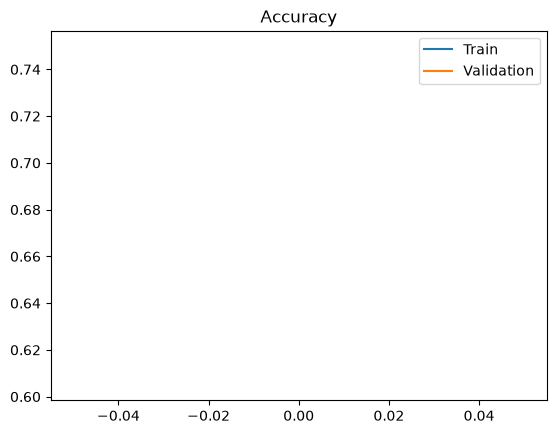

In [7]:
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.legend()
plt.show()

In [8]:
images, labels = next(iter(test_ds))
pred = model.predict(images[:5])
for i in range(5):
    print("Actual:", class_names[labels[i]], "| Predicted:", class_names[np.argmax(pred[i])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step
Actual: dandelion | Predicted: dandelion
Actual: tulips | Predicted: tulips
Actual: dandelion | Predicted: dandelion
Actual: tulips | Predicted: tulips
Actual: dandelion | Predicted: dandelion
